# Working with Sequences

We start the practice by installing the book libraries and importing some of them:

In [1]:
%matplotlib inline
import torch
from torch import nn
from d2l import torch as d2l

## Autoregressive Models

Our target data will be a synthetic data set built on the sinusoidal function SIN. We create 1000 data points within the DATA class but corrupt their values by adding some random noise.

```python
self.x = torch.sin(0.01 * self.time) + torch.randn(T) * 0.2
```

We first define some initialization parameters:

- Batch size = 16
- T = 1000 (size of the sequence)
- num_train (training samples)
- tau = 4 (4 points will be used to estimate our next sample) (Markov problem of order 4)

In [2]:
class Data(d2l.DataModule):
    def __init__(self, batch_size=16, T=1000, num_train=600, tau=4):
        self.save_hyperparameters()
        self.time = torch.arange(1, T + 1, dtype=torch.float32)
        self.x = torch.sin(0.01 * self.time) + torch.randn(T) * 0.2

Let's verify the type of structure we are using (Torch Tensors) and print the created data.

<class 'torch.Tensor'>
<class 'torch.Tensor'>


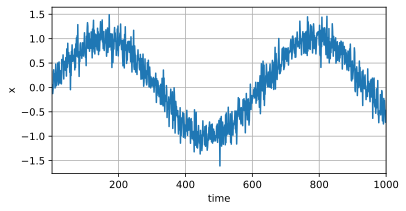

In [3]:
data = Data()
print(type(data.time))
print(type(data.x))
d2l.plot(data.time, data.x, "time", "x", xlim=[1, 1000], figsize=(6, 3))

To begin, we try a model that acts as if the data satisfied a $\tau^{\textrm{th}}$-order Markov condition, and thus predicts $x_t$ using only the past $\tau$ observations. (We set it up originally to 4, you should try other values as well).

[**Thus for each time step we have an example with label $y  = x_t$ and features $\mathbf{x}_t = [x_{t-\tau}, \ldots, x_{t-1}]$.**]


In [4]:
@d2l.add_to_class(Data)
def get_dataloader(self, train):
    features = [self.x[i : self.T-self.tau+i] for i in range(self.tau)]
    self.features = torch.stack(features, 1)
    self.labels = self.x[self.tau:].reshape((-1, 1))
    i = slice(0, self.num_train) if train else slice(self.num_train, None)
    return self.get_tensorloader([self.features, self.labels], train, i)

In this example our model will be a simple standard linear regression. You can consult early chapters of the book "Dive into DL" (D2l)  to see some more details of it. At this moment, we are not much interesting on the model used. We will analyze relevant models later.

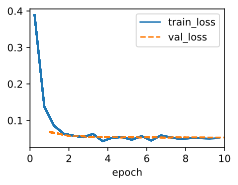

In [5]:
model = d2l.LinearRegression(lr=0.01)
trainer = d2l.Trainer(max_epochs=10)
trainer.fit(model, data)

## Prediction

To evaluate our model, we first check how well it performs at one-step-ahead prediction.

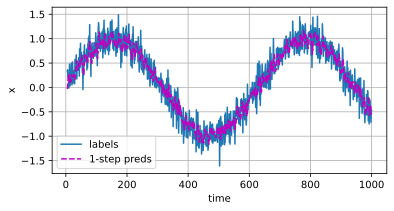

In [6]:
onestep_preds = model(data.features).detach().numpy()
d2l.plot(data.time[data.tau:], [data.labels, onestep_preds], "time", "x",
         legend=["labels", "1-step preds"], figsize=(6, 3))

These predictions look good, even near the end at $t=1000$.

But what if we only observed sequence data up until time step 604 (`n_train + tau`) and wished to make predictions several steps into the future? Unfortunately, we cannot directly compute the one-step-ahead prediction for time step 609, because we do not know the corresponding inputs, having seen only up to $x_{604}$. We can address this problem by plugging in our earlier predictions as inputs to our model for making subsequent predictions, projecting forward, one step at a time, until reaching the desired time step:

$$\begin{aligned}
\hat{x}_{605} &= f(x_{601}, x_{602}, x_{603}, x_{604}), \\
\hat{x}_{606} &= f(x_{602}, x_{603}, x_{604}, \hat{x}_{605}), \\
\hat{x}_{607} &= f(x_{603}, x_{604}, \hat{x}_{605}, \hat{x}_{606}),\\
\hat{x}_{608} &= f(x_{604}, \hat{x}_{605}, \hat{x}_{606}, \hat{x}_{607}),\\
\hat{x}_{609} &= f(\hat{x}_{605}, \hat{x}_{606}, \hat{x}_{607}, \hat{x}_{608}),\\
&\vdots\end{aligned}$$

Generally, for an observed sequence $x_1, \ldots, x_t$, its predicted output $\hat{x}_{t+k}$ at time step $t+k$ is called the $k$*-step-ahead prediction*. Since we have observed up to $x_{604}$, its $k$-step-ahead prediction is $\hat{x}_{604+k}$. In other words, we will have to keep on using our own predictions to make multistep-ahead predictions. Let"s see how well this goes.

In [7]:
multistep_preds = torch.zeros(data.T)
multistep_preds[:] = data.x
for i in range(data.num_train + data.tau, data.T):
    multistep_preds[i] = model(
        multistep_preds[i - data.tau:i].reshape((1, -1)))
multistep_preds = multistep_preds.detach().numpy()

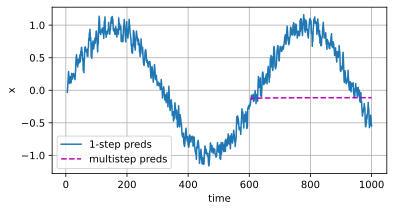

In [8]:
d2l.plot([data.time[data.tau:], data.time[data.num_train+data.tau:]],
         [onestep_preds, multistep_preds[data.num_train+data.tau:]], "time",
         "x", legend=["1-step preds", "multistep preds"], figsize=(6, 3))

Unfortunately, in this case we fail spectacularly. The predictions decay to a constant pretty quickly after a few steps. Why did the algorithm perform so much worse when predicting further into the future? Ultimately, this is down to the fact that errors build up. Let"s say that after step 1 we have some error $\epsilon_1 = \bar\epsilon$. Now the *input* for step 2 is perturbed by $\epsilon_1$, hence we suffer some error in the order of $\epsilon_2 = \bar\epsilon + c \epsilon_1$ for some constant $c$, and so on. The predictions can diverge rapidly from the true observations. You may already be familiar with this common phenomenon. For instance, weather forecasts for the next 24 hours tend to be pretty accurate but beyond that, accuracy declines rapidly. We will discuss methods for improving this throughout this chapter and beyond.

Let"s [**take a closer look at the difficulties in $k$-step-ahead predictions**] by computing predictions on the entire sequence for $k = 1, 4, 16, 64$.

In [9]:
def k_step_pred(k):
    features = []
    for i in range(data.tau):
        features.append(data.x[i : i+data.T-data.tau-k+1])
    # The (i+tau)-th element stores the (i+1)-step-ahead predictions
    for i in range(k):
        preds = model(torch.stack(features[i : i+data.tau], 1))
        features.append(preds.reshape(-1))
    return features[data.tau:]

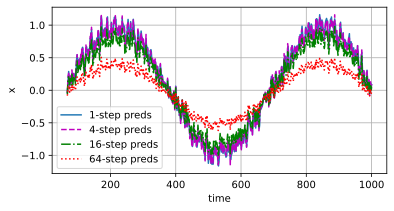

In [10]:
steps = (1, 4, 16, 64)
preds = k_step_pred(steps[-1])
d2l.plot(data.time[data.tau+steps[-1]-1:],
         [preds[k - 1].detach().numpy() for k in steps], "time", "x",
         legend=[f"{k}-step preds" for k in steps], figsize=(6, 3))

This clearly illustrates how the quality of the prediction changes as we try to predict further into the future. While the 4-step-ahead predictions still look good, anything beyond that is starts to get worse.


## P0-Exercises

1. Improve the model in the experiment of this section. Modify the number of past observations used for predictions. What seems to be the optimal value? Justify.
2. With a chosen value of $\tau$ compare results for future predictions at different times, showing the error obtained.
3. Repeat the whole analysis with a real data set:
    - Option a) ibm.us.txt : Stock Market predictions
    - Option b) daily-min-temperaturas.csv : Daily Temperature values

    Extract conclusions. Compute the MSE o MAE for different cases.
4. Theory: Autoregressive vs Autoregressive latent models. Look for an example that might need latent variables to capture the dynamic of the data. Explain.


## Resolución de los ejercicios P0

Se resuelven los cuatro ejercicios reutilizando `Data`, la regresión lineal y las funciones anteriores. Se usan MSE y MAE, evaluando preferentemente sobre el tramo de test para medir la generalización.

### Ejercicio 1. Influencia del número de observaciones pasadas ($\tau$)

Se entrena la misma regresión lineal para los valores 1, 2, 4, 8, 16, 32 y 64 de $\tau$, con 10 épocas, lr=0.01, 600 puntos de train y 3 semillas. Se comparan MSE y MAE sobre test.

Mejor tau por MSE de test: 8 | mejor tau por MAE de test: 32


,tau,MSE_train,MAE_train,MSE_test,MAE_test,MSE_test_std,MAE_test_std
0,1,0.078851,0.223079,0.082695,0.229552,0.005807,0.007790
1,2,0.063879,0.200449,0.065785,0.204952,0.005483,0.009132
2,4,0.056605,0.190359,0.056915,0.187604,0.008900,0.012777
3,8,0.051403,0.181631,0.050968,0.178892,0.004027,0.006351
4,16,0.051344,0.180169,0.051447,0.180678,0.004442,0.007065
5,32,0.052199,0.181618,0.051352,0.178683,0.004951,0.006196
6,64,0.053673,0.184523,0.053379,0.185643,0.001652,0.001353


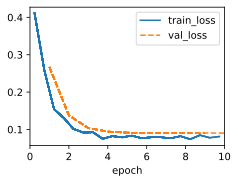

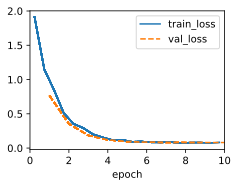

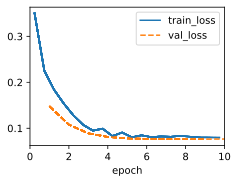

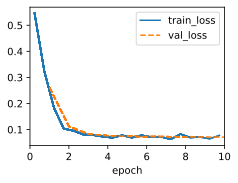

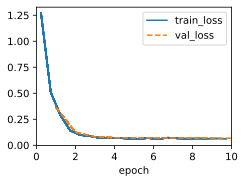

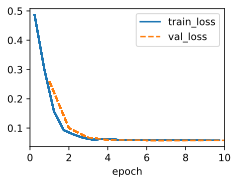

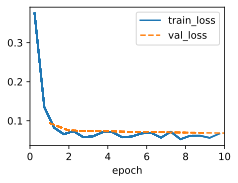

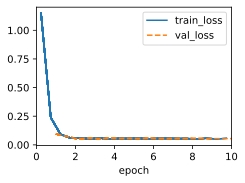

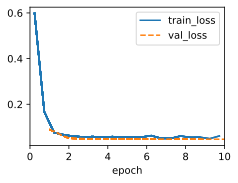

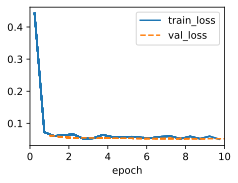

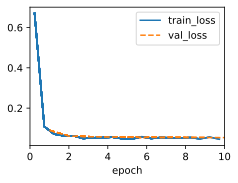

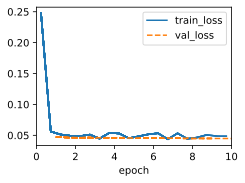

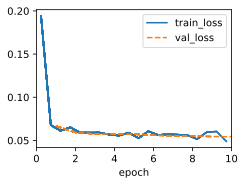

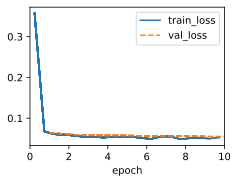

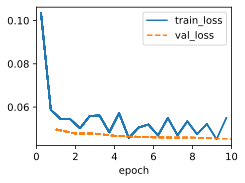

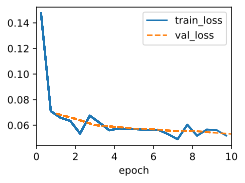

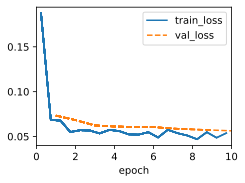

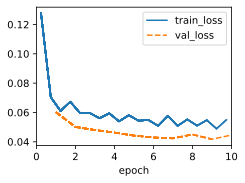

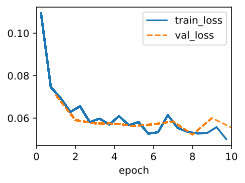

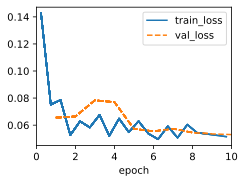

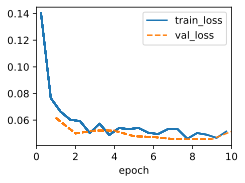

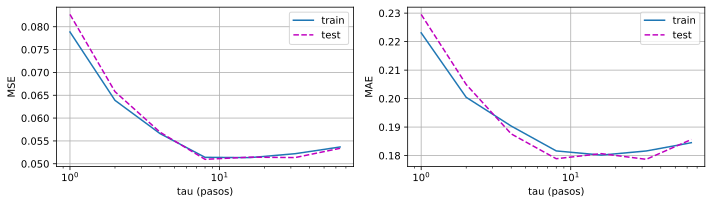

In [11]:
import numpy as np
import pandas as pd

def train_ar_model(data, epochs=10, lr=0.01):
    model = d2l.LinearRegression(lr=lr)
    d2l.Trainer(max_epochs=epochs).fit(model, data)
    return model

@torch.no_grad()
def one_step_metrics(data, model, train=False):
    idx = slice(0, data.num_train) if train else slice(data.num_train, None)
    y, y_hat = data.labels[idx], model(data.features[idx])
    return (nn.functional.mse_loss(y_hat, y).item(),
            nn.functional.l1_loss(y_hat, y).item())

taus_to_try = [1, 2, 4, 8, 16, 32, 64]
seeds = [0, 1, 2]
rows = []
for tau in taus_to_try:
    metrics_for_tau = []
    for seed in seeds:
        torch.manual_seed(seed)
        dataset = Data(tau=tau)
        trained = train_ar_model(dataset, epochs=10)
        mse_train, mae_train = one_step_metrics(dataset, trained, train=True)
        mse_test, mae_test = one_step_metrics(dataset, trained, train=False)
        metrics_for_tau.append((mse_train, mae_train, mse_test, mae_test))
    metrics_for_tau = np.array(metrics_for_tau)
    rows.append({
        "tau": tau,
        "MSE_train": metrics_for_tau[:, 0].mean(),
        "MAE_train": metrics_for_tau[:, 1].mean(),
        "MSE_test": metrics_for_tau[:, 2].mean(),
        "MAE_test": metrics_for_tau[:, 3].mean(),
        "MSE_test_std": metrics_for_tau[:, 2].std(),
        "MAE_test_std": metrics_for_tau[:, 3].std(),
    })

tau_results = pd.DataFrame(rows)
best_tau = int(tau_results.loc[tau_results["MSE_test"].idxmin(), "tau"])
best_tau_mae = int(tau_results.loc[tau_results["MAE_test"].idxmin(), "tau"])
print(f"Mejor tau por MSE de test: {best_tau} | mejor tau por MAE de test: {best_tau_mae}")
fig, axes = d2l.plt.subplots(1, 2, figsize=(10, 3))
d2l.plot(tau_results["tau"], [tau_results["MSE_train"], tau_results["MSE_test"]],
         "tau (pasos)", "MSE", legend=["train", "test"], xscale="log",
         axes=axes[0])
d2l.plot(tau_results["tau"], [tau_results["MAE_train"], tau_results["MAE_test"]],
         "tau (pasos)", "MAE", legend=["train", "test"], xscale="log",
         axes=axes[1])
fig.tight_layout()
tau_results


El error de test baja de $\tau=1$ a $\tau=8$ y luego se estabiliza: un $\tau$ pequeño no captura la dinámica sinusoidal y uno grande añade parámetros y sensibilidad al ruido. El MSE mínimo está en $\tau=8$ ($\approx 0.0510$); el MAE mínimo aparece en $\tau=32$ ($\approx 0.1787$), casi idéntico al de $\tau=8$ ($\approx 0.1789$). Se elige $\tau=8$ como compromiso; $\tau=64$ empeora ligeramente.

### Ejercicio 2. Predicciones a $k$ pasos y error

Con el valor $\tau=8$ del ejercicio anterior se entrena el modelo final y se generan predicciones recursivas a $k$ pasos: cada predicción se realimenta como entrada del siguiente paso. Se evalúan los mismos instantes de test para todos los horizontes, usando las $\tau$ observaciones reales anteriores a cada origen y alineando cada predicción con su instante objetivo.

,k,n_test,MSE,MAE
0,1,392,0.056250,0.191739
1,2,392,0.057214,0.194159
2,4,392,0.060670,0.197849
3,8,392,0.063849,0.201319
4,16,392,0.068163,0.210226
5,32,392,0.129351,0.297833
6,64,392,0.355800,0.524607


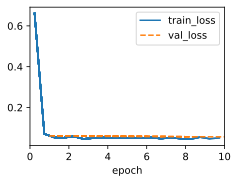

In [12]:
torch.manual_seed(42)
synth_data = Data(tau=best_tau)
synth_model = train_ar_model(synth_data, epochs=10)

@torch.no_grad()
def k_step_forecasts(data, model, k):
    features = [data.x[i : i + data.T - data.tau - k + 1] for i in range(data.tau)]
    for i in range(k):
        pred = model(torch.stack(features[i:i + data.tau], 1)).reshape(-1)
        features.append(pred)
    return features[data.tau + k - 1].detach()

def horizon_errors(data, model, horizons):
    first_unknown = data.num_train + data.tau
    rows = []
    for k in horizons:
        preds = k_step_forecasts(data, model, k)
        targets = data.x[data.tau + k - 1:]
        target_idx = torch.arange(data.tau + k - 1, data.T)
        mask = target_idx >= first_unknown
        p, y = preds[mask], targets[mask]
        mse = nn.functional.mse_loss(p, y).item()
        rows.append({
            "k": k,
            "n_test": int(mask.sum()),
            "MSE": mse,
            "MAE": nn.functional.l1_loss(p, y).item(),
        })
    return pd.DataFrame(rows)

horizons = [1, 2, 4, 8, 16, 32, 64]
synth_errors = horizon_errors(synth_data, synth_model, horizons)
synth_errors

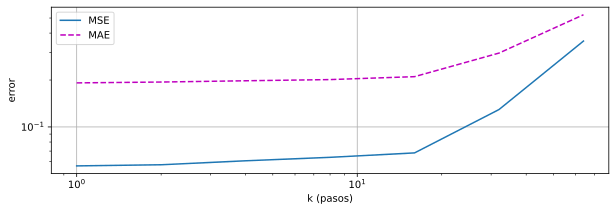

In [13]:
d2l.plot(synth_errors["k"], [synth_errors["MSE"], synth_errors["MAE"]],
         "k (pasos)", "error", legend=["MSE", "MAE"], xscale="log",
         yscale="log", figsize=(10, 3))

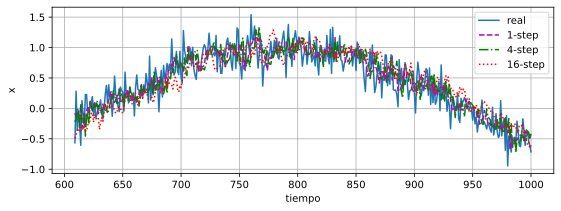

In [14]:
first_unknown = synth_data.num_train + synth_data.tau
curves = [synth_data.x[first_unknown:]]
labels = ["real"]
for k in [1, 4, 16, 64]:
    preds = k_step_forecasts(synth_data, synth_model, k)
    target_idx = torch.arange(synth_data.tau + k - 1, synth_data.T)
    curves.append(preds[target_idx >= first_unknown])
    labels.append(f"{k}-step")
d2l.plot(synth_data.time[first_unknown:], curves, "tiempo", "x",
         legend=labels, figsize=(9, 3))

El error crece con el horizonte $k$: el MSE pasa de $0.056$ ($k=1$) a $0.356$ ($k=64$) y el MAE de $\approx 0.192$ a $\approx 0.525$. El crecimiento es suave hasta $k\approx 8$ y se acelera después por la acumulación de errores al realimentar las propias predicciones.

### Ejercicio 3. Análisis con datos reales

Se usa `daily-min-temperatures.csv` (3650 días, 1981-1990), con split 80/20. La temperatura se estandariza con la media y la desviación del tramo de train, y los errores se devuelven a °C.

Fichero: ../data/daily-min-temperatures.csv | días: 3650 | train: 2920 | test: 730


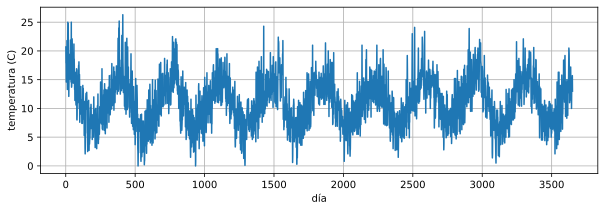

In [15]:
csv_path = "../data/daily-min-temperatures.csv"

class TemperatureData(d2l.DataModule):
    def __init__(self, csv_path, batch_size=32, tau=4, train_ratio=0.8):
        self.save_hyperparameters()
        frame = pd.read_csv(csv_path)
        raw = torch.tensor(frame["Temp"].to_numpy(), dtype=torch.float32)
        self.raw = raw
        self.T = len(raw)
        self.num_train = int(self.T * train_ratio)
        train_part = raw[:self.num_train]
        self.mean = train_part.mean()
        self.std = train_part.std()
        self.x = (raw - self.mean) / self.std
        self.time = torch.arange(1, self.T + 1, dtype=torch.float32)

@d2l.add_to_class(TemperatureData)
def get_dataloader(self, train):
    features = [self.x[i : self.T-self.tau+i] for i in range(self.tau)]
    self.features = torch.stack(features, 1)
    self.labels = self.x[self.tau:].reshape((-1, 1))
    i = slice(0, self.num_train) if train else slice(self.num_train, None)
    return self.get_tensorloader([self.features, self.labels], train, i)

temperature = TemperatureData(csv_path=csv_path)
print(f"Fichero: {temperature.csv_path} | días: {temperature.T} | train: {temperature.num_train} "
      f"| test: {temperature.T - temperature.num_train}")
d2l.plot(temperature.time, temperature.raw, "día", "temperatura (C)",
         figsize=(10, 3))

Se repite el estudio de $\tau$ con 20 épocas, 3 semillas y el 20\% final como test, probando valores de 1 a 60 días (1, 2, 4, 7, 14, 30 y 60).

Mejor tau para temperatura por MSE: 30 | por MAE: 30


,tau,MSE_train,MAE_train,MSE_test,MAE_test,MSE_test_std
0,1,0.415988,0.500200,0.343415,0.467362,0.000904
1,2,0.413761,0.499648,0.339862,0.463974,0.000369
2,4,0.390326,0.486437,0.317193,0.443826,0.000560
3,7,0.376596,0.480142,0.305684,0.435177,0.001361
4,14,0.370557,0.475490,0.304983,0.435830,0.005095
5,30,0.361721,0.472018,0.298156,0.428878,0.001152
6,60,0.361204,0.476509,0.311605,0.440905,0.007065


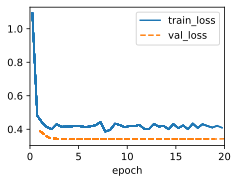

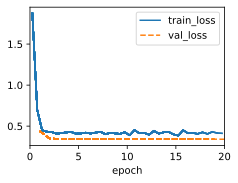

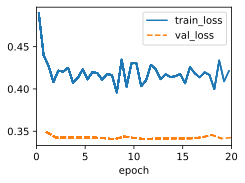

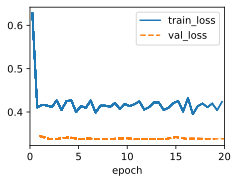

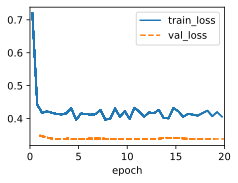

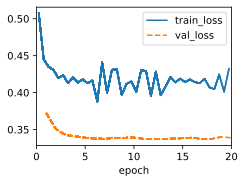

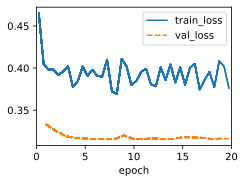

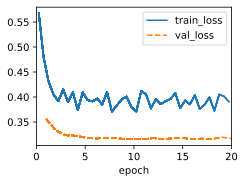

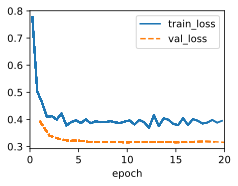

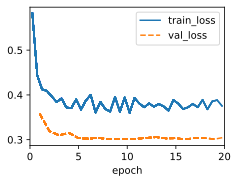

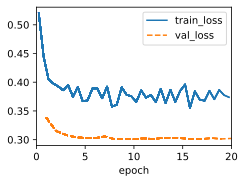

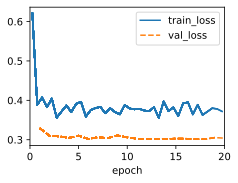

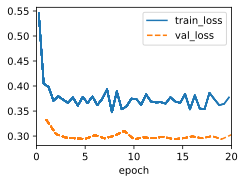

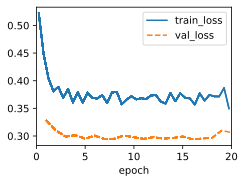

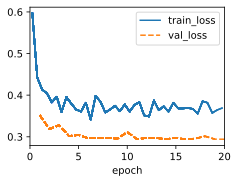

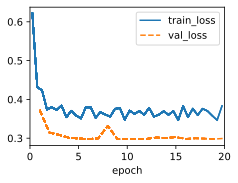

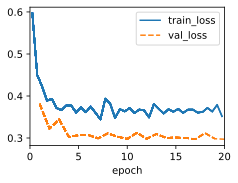

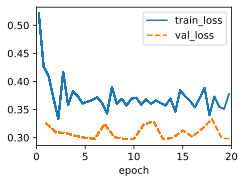

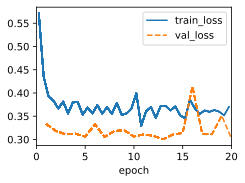

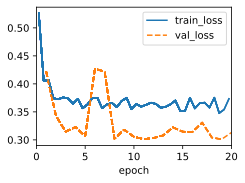

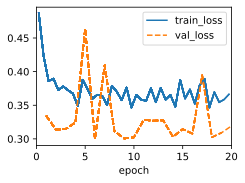

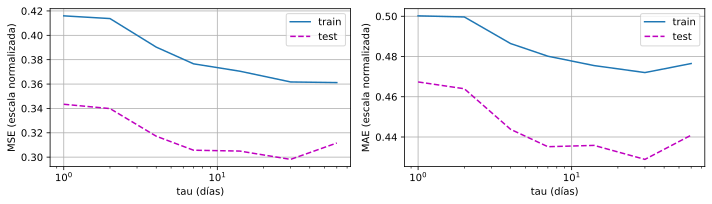

In [16]:
temp_taus = [1, 2, 4, 7, 14, 30, 60]
temp_rows = []
for tau in temp_taus:
    metrics_for_tau = []
    for seed in seeds:
        torch.manual_seed(seed)
        dataset = TemperatureData(csv_path=csv_path, tau=tau)
        trained = train_ar_model(dataset, epochs=20)
        mse_train, mae_train = one_step_metrics(dataset, trained, train=True)
        mse_test, mae_test = one_step_metrics(dataset, trained, train=False)
        metrics_for_tau.append((mse_train, mae_train, mse_test, mae_test))
    metrics_for_tau = np.array(metrics_for_tau)
    temp_rows.append({
        "tau": tau,
        "MSE_train": metrics_for_tau[:, 0].mean(),
        "MAE_train": metrics_for_tau[:, 1].mean(),
        "MSE_test": metrics_for_tau[:, 2].mean(),
        "MAE_test": metrics_for_tau[:, 3].mean(),
        "MSE_test_std": metrics_for_tau[:, 2].std(),
    })

temp_results = pd.DataFrame(temp_rows)
temp_best_tau = int(temp_results.loc[temp_results["MSE_test"].idxmin(), "tau"])
temp_best_tau_mae = int(temp_results.loc[temp_results["MAE_test"].idxmin(), "tau"])
print(f"Mejor tau para temperatura por MSE: {temp_best_tau} "
      f"| por MAE: {temp_best_tau_mae}")
fig, axes = d2l.plt.subplots(1, 2, figsize=(10, 3))
d2l.plot(temp_results["tau"], [temp_results["MSE_train"], temp_results["MSE_test"]],
         "tau (días)", "MSE (escala normalizada)", legend=["train", "test"],
         xscale="log", axes=axes[0])
d2l.plot(temp_results["tau"], [temp_results["MAE_train"], temp_results["MAE_test"]],
         "tau (días)", "MAE (escala normalizada)", legend=["train", "test"],
         xscale="log", axes=axes[1])
fig.tight_layout()
temp_results


El mejor resultado se obtiene con **$\tau=30$** (un mes), con un MSE de test $\approx 0.298$ en escala normalizada. Valores pequeños no capturan la persistencia ni la variación suave, y 60 días añade parámetros y ruido. Es un compromiso entre contexto y complejidad.

Con $\tau=30$ se calculan los errores a distintos horizontes de forma recursiva. Además de la tabla en escala normalizada, se incluyen las métricas en °C (MSE en °C² y MAE en °C).

Test 1 paso: MSE=0.2966 (4.891 C^2), MAE=0.4279 (1.737 C)


,k,n_test,MSE,MAE,MSE_C,MAE_C
0,1,700,0.296624,0.427867,4.890912,1.737403
1,2,700,0.410384,0.494259,6.766646,2.006994
2,4,700,0.444058,0.513818,7.321891,2.086415
3,7,700,0.462789,0.524202,7.630727,2.128582
4,14,700,0.509363,0.553626,8.398672,2.248062
5,30,700,0.636991,0.625717,10.503071,2.540794
6,60,700,0.950477,0.788880,15.672023,3.203336


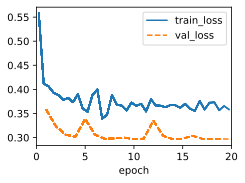

In [17]:
torch.manual_seed(42)
temp_data = TemperatureData(csv_path=csv_path, tau=temp_best_tau)
temp_model = train_ar_model(temp_data, epochs=20)
mse_test, mae_test = one_step_metrics(temp_data, temp_model, train=False)
print(f"Test 1 paso: MSE={mse_test:.4f} ({mse_test * temp_data.std.item()**2:.3f} C^2), "
      f"MAE={mae_test:.4f} ({mae_test * temp_data.std.item():.3f} C)")

temp_horizons = [1, 2, 4, 7, 14, 30, 60]
temp_errors = horizon_errors(temp_data, temp_model, temp_horizons)
temp_errors["MSE_C"] = temp_errors["MSE"] * temp_data.std.item()**2
temp_errors["MAE_C"] = temp_errors["MAE"] * temp_data.std.item()
temp_errors

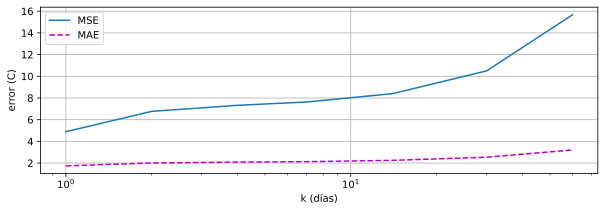

In [18]:
d2l.plot(temp_errors["k"], [temp_errors["MSE_C"], temp_errors["MAE_C"]],
         "k (días)", "error (C)", legend=["MSE", "MAE"], xscale="log",
         figsize=(10, 3))

Pronóstico de 60 días: MSE=9.572 C^2, MAE=2.518 C


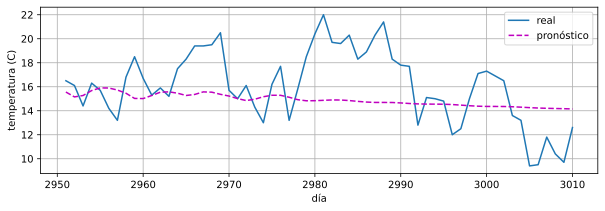

In [19]:
first_unknown = temp_data.num_train + temp_data.tau
history = temp_data.x[first_unknown - temp_data.tau:first_unknown].clone()
forecast = []
for _ in range(60):
    next_value = temp_model(history[-temp_data.tau:].reshape((1, -1)))
    history = torch.cat([history, next_value.reshape(1)])
    forecast.append(next_value.item())
forecast = torch.tensor(forecast) * temp_data.std + temp_data.mean
truth = temp_data.raw[first_unknown:first_unknown + 60]
print(f"Pronóstico de 60 días: MSE={((forecast - truth)**2).mean():.3f} C^2, "
      f"MAE={(forecast - truth).abs().mean():.3f} C")
d2l.plot(temp_data.time[first_unknown:first_unknown + 60], [truth, forecast],
         "día", "temperatura (C)", legend=["real", "pronóstico"], figsize=(10, 3))

**Conclusiones del ejercicio 3.** El modelo aprende bien la persistencia a corto plazo: a un paso el MAE es ≈ 1.74 °C (RMSE ≈ 2.21 °C); a 2 días ronda 2.0 °C y a 60 días supera 3.2 °C. El pronóstico concreto de 60 días da un MAE de 2.52 °C. Al realimentar las predicciones el error se acumula y el modelo tiende a la media, por lo que no reproduce la estacionalidad anual. Para mejorar harían falta más variables (por ejemplo, la estación) o modelos con estado latente.

### Ejercicio 4. Teoría: modelos autorregresivos frente a autorregresivos latentes

Un **modelo autorregresivo (AR)** explica el valor actual a partir de valores pasados observados:
$$x_t = f(x_{t-1}, x_{t-2}, \ldots, x_{t-\tau}) + \varepsilon_t.$$
La dinámica se supone contenida en las observaciones pasadas; es el supuesto del modelo lineal de esta práctica.

Un **modelo autorregresivo latente** introduce una variable de estado no observada $z_t$ que evoluciona de forma autorregresiva y que genera las observaciones:
$$z_t = g(z_{t-1}) + \eta_t, \qquad x_t = h(z_t) + \varepsilon_t.$$
La dependencia temporal pasa por el estado latente. Ejemplos: espacio de estados/Kalman, HMM y DeepAR, donde una red recurrente mantiene un estado interno.

Un caso típico son los cambios de régimen no observados: en finanzas la volatilidad no se observa y un AR sobre precios no anticipa bien los cambios de calma a alta volatilidad; un HMM o un modelo de volatilidad estocástica introduce un régimen latente. Algo similar ocurre con frentes meteorológicos no observados en la temperatura.

También se necesitan variables latentes con observaciones faltantes o ruido de medida: un AR se queda sin entradas, mientras que un modelo de espacio de estados sigue actualizando su estado. Ejemplo: el GPS en un túnel; con la velocidad y dirección latentes se puede seguir estimando la posición.

## Conclusiones generales

- **Serie sintética:** con $\tau=8$, MSE de test $\approx 0.051$ y MAE $\approx 0.179$; el error a $k$ pasos crece de $0.056$ ($k=1$) a $0.356$ ($k=64$) por la acumulación de errores.
- **Temperatura:** el óptimo es $\tau=30$ (MSE de test $\approx 0.298$); el MAE pasa de $\approx 1.74$ °C a 1 paso a $\approx 3.20$ °C a 60 días. Captura la persistencia diaria, no la estacionalidad anual.
- **AR frente a AR latente:** el AR solo usa observaciones pasadas; si la dinámica depende de estados no observados (volatilidad, regímenes, GPS en un túnel), se necesita un estado latente (Kalman, HMM, DeepAR).
- **Mejoras:** el modelo lineal es una buena base, pero no captura no linealidades ni estacionalidad; conviene añadir variables exógenas (por ejemplo, la estación) o usar modelos con estado latente.